In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
# Folder proyek dan hasil pengolahan data
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data" / "processed"

In [4]:
# 1. Membaca matriks VSM User yang sudah dibuat
vsm_user = sp.load_npz(DATA_DIR / "VSM_user_P1.npz")

In [5]:
# 2. Membalik baris dan kolom untuk membentuk VSM Item
vsm_item = vsm_user.transpose().tocsr()

In [6]:
# 3. Menyimpan matriks VSM Item
sp.save_npz(DATA_DIR / "VSM_item_P1.npz", vsm_item)

In [7]:
# 4. Menampilkan karakteristik matriks
jumlah_item, jumlah_user = vsm_item.shape
jumlah_interaksi = vsm_item.nnz
total_sel = jumlah_item * jumlah_user

density = jumlah_interaksi / total_sel
sparsity = 1 - density

print("===== KARAKTERISTIK VSM ITEM P1 =====")
print(f"Jumlah Item       : {jumlah_item:,}")
print(f"Jumlah User       : {jumlah_user:,}")
print(f"Shape matriks     : {vsm_item.shape}")
print(f"Jumlah interaksi  : {jumlah_interaksi:,}")
print(f"Density           : {density * 100:.8f}%")
print(f"Sparsity          : {sparsity * 100:.8f}%")
print(f"Jumlah sel matriks: {total_sel:,}")
print(
    "Ukuran data nonzero: "
    f"{vsm_item.data.nbytes:,} byte"
)

===== KARAKTERISTIK VSM ITEM P1 =====
Jumlah Item       : 87,308
Jumlah User       : 185,205
Shape matriks     : (87308, 185205)
Jumlah interaksi  : 266,342
Density           : 0.00164715%
Sparsity          : 99.99835285%
Jumlah sel matriks: 16,169,878,140
Ukuran data nonzero: 266,342 byte


In [8]:
# 5. Membuat graf bipartit dari sampel interaksi
#    Ambil 25 pasangan Item-User yang tercatat
baris, kolom = vsm_item.nonzero()
jumlah_sampel = min(25, len(baris))

G = nx.Graph()

for idx in range(jumlah_sampel):
    item_idx = int(baris[idx])
    user_idx = int(kolom[idx])

    item_node = f"Item {item_idx}"
    user_node = f"User {user_idx}"

    G.add_node(item_node, bipartite="item")
    G.add_node(user_node, bipartite="user")
    G.add_edge(item_node, user_node)

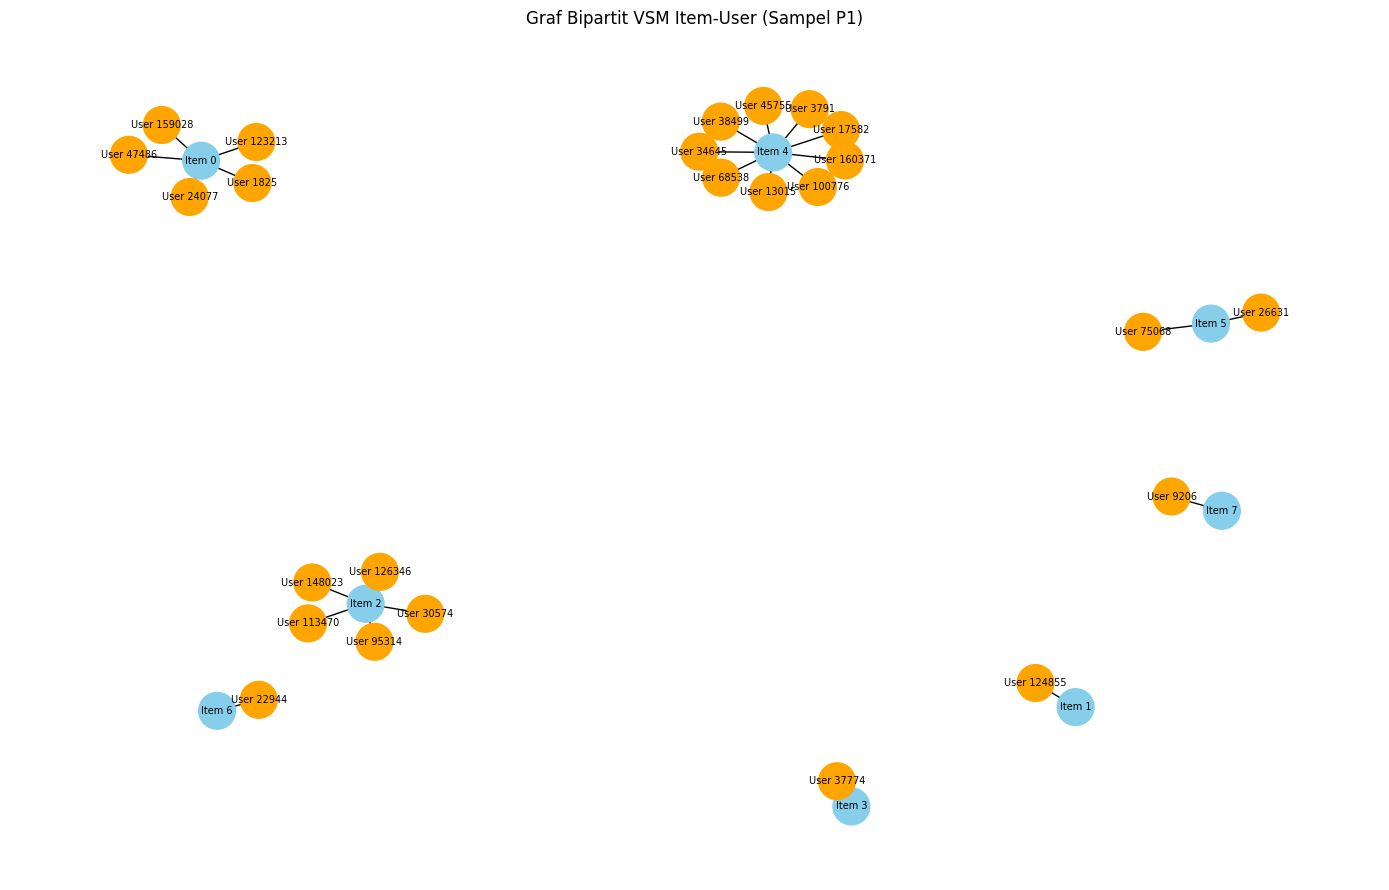


===== GRAF NETWORKX =====
Jumlah node sampel : 33
Jumlah edge sampel : 25
Gambar disimpan di : c:\Users\ADVAN\UTS-GSD-Rebriane-24031554039\data\processed\networkx_item_user_P1.png

Matriks VSM Item berhasil disimpan.


In [9]:
# 6. Menggambar graf
pos = nx.spring_layout(G, seed=42)

warna = [
    "skyblue" if G.nodes[n]["bipartite"] == "item"
    else "orange"
    for n in G.nodes()
]

plt.figure(figsize=(14, 9))
nx.draw_networkx(
    G,
    pos,
    node_color=warna,
    node_size=700,
    font_size=7,
    with_labels=True
)

plt.title("Graf Bipartit VSM Item-User (Sampel P1)")
plt.axis("off")
plt.tight_layout()

output_gambar = DATA_DIR / "networkx_item_user_P1.png"
plt.savefig(output_gambar, dpi=200, bbox_inches="tight")
plt.show()

print("\n===== GRAF NETWORKX =====")
print(f"Jumlah node sampel : {G.number_of_nodes()}")
print(f"Jumlah edge sampel : {G.number_of_edges()}")
print(f"Gambar disimpan di : {output_gambar}")
print("\nMatriks VSM Item berhasil disimpan.")
